# Part 3 — Metrics definition and Analysis
**LOG6307E · Mining Human–AI Collaboration in Software Engineering Repositories**

**RQ1:** **Development outcomes** — How do AI-related contributions differ from human
contributions in terms of development outcomes?

In [53]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv("data/cleaned_pull_requests.csv")

**Metrics included**

- **Merge rate:** proportion of closed PRs that were merged.
- **Time to merge:** elapsed time from PR creation to merge, for merged PRs only.
- **Time to close:** elapsed time from PR creation to closure, for all closed PRs (merged and unmerged).
- **Review participation:** number of reviews, reviewers, and review comments per PR.
- **Commits per PR:** number of commits associated with each PR.

**1. Merge rate**

**Merge rate** measures the percentage of closed pull requests that were merged. **Open PRs are excluded** because their outcomes are not yet final.

<div align="center">

$$\text{Merge rate} = \frac{\text{Merged closed PRs}}{\text{Closed PRs}} \times 100$$

</div>

In [77]:
def merge_rate(prs):
    closed_prs = prs[prs["state"] == "closed"]

    result = closed_prs.groupby("contribution_type").agg(
        total_prs=("pr_id", "count"),
        merged_prs=("merged", "sum")
    )

    result["merge_rate"] = (result["merged_prs"] / result["total_prs"] * 100).round(2)

    return result.reset_index()

merge_results = merge_rate(data)
merge_results

,contribution_type,total_prs,merged_prs,merge_rate
0,AI,31255,23989,76.75
1,Human,6135,5070,82.64


**2. Time to merge**

**Time to merge** measures the elapsed time between the creation of a pull request and its merge.
The calculation is:

$$
\text{Time to merge} = \text{merged\_at} - \text{created\_at}
$$

In [78]:
def time_to_merge(prs):
    merged_prs = prs[prs["merged"] == True]

    merged_prs["created_at"] = pd.to_datetime(merged_prs["created_at"])
    merged_prs["merged_at"] = pd.to_datetime(merged_prs["merged_at"])

    merged_prs["time_to_merge"] = (merged_prs["merged_at"] - merged_prs["created_at"]).dt.total_seconds() / 3600

    return merged_prs

merge_times = time_to_merge(data)

merge_time_results = (
    merge_times
    .groupby("contribution_type")["time_to_merge"]
    .agg(
        number_of_prs="count",
        mean_hours="mean",
        median_hours="median",
        minimum_hours="min",
        maximum_hours="max"
    )
    .round(2)
)

merge_time_results

,number_of_prs,mean_hours,median_hours,minimum_hours,maximum_hours
contribution_type,,,,,
AI,23989,19.43,0.05,0.0,1797.70
Human,5070,63.62,3.90,0.0,3220.46


**3. Time to close**

**Time to close** measures the elapsed time between the creation and closing of a pull request.
The calculation is:

$$
\text{Time to close} = \text{closed\_at} - \text{created\_at}
$$

*This metric includes both merged and closed-unmerged pull requests.*

In [73]:
def time_to_close(prs):
    closed_prs = prs[prs["state"] == "closed"]

    closed_prs["created_at"] = pd.to_datetime(closed_prs["created_at"])

    closed_prs["closed_at"] = pd.to_datetime(closed_prs["closed_at"])

    closed_prs["time_to_close"] = (closed_prs["closed_at"] - closed_prs["created_at"]).dt.total_seconds() / 3600

    return closed_prs

    close_times = time_to_close(data)

close_time_results = (
    close_times
    .groupby("contribution_type")["time_to_close"]
    .agg(
        number_of_prs="count",
        mean_hours="mean",
        median_hours="median",
        minimum_hours="min",
        maximum_hours="max"
    )
    .round(2)
)

close_time_results

,number_of_prs,mean_hours,median_hours,minimum_hours,maximum_hours
contribution_type,,,,,
AI,31255,40.45,0.12,0.0,3549.19
Human,6135,93.16,5.37,0.0,3815.92


**4. Review participation**

**Review participation** describes the review process rather than whether a PR was successful. The table reports the **mean** and **median** number of reviews, reviewers, and review comments for each contribution type.

In [57]:
def review_participation(prs):
    result = (
        prs
        .groupby("contribution_type")
        .agg(
            number_of_prs=("pr_id", "count"),
            mean_reviews=("n_reviews", "mean"),
            median_reviews=("n_reviews", "median"),
            mean_reviewers=("n_reviewers", "mean"),
            median_reviewers=("n_reviewers", "median"),
            mean_review_comments=("n_review_comments", "mean"),
            median_review_comments=("n_review_comments", "median")
        )
    )

    return result.round(2).reset_index()

review_results = review_participation(data)
review_results

,contribution_type,number_of_prs,mean_reviews,median_reviews,mean_reviewers,median_reviewers,mean_review_comments,median_review_comments
0,AI,33566,0.86,0.0,0.4,0.0,0.8,0.0
1,Human,6592,0.00,0.0,0.0,0.0,0.0,0.0


**5. Commits per PR**

This table summarizes the **number of commits associated with each PR**. 

*This is only done with AI commits given that the available dataset does not provide commit records that can be joined to those human PRs using the current key.*

In [58]:
def commits_per_pr(prs):
    commits = prs.dropna(subset=["n_commits"])

    result = (
        commits
        .groupby("contribution_type")["n_commits"]
        .agg(
            number_of_prs="count",
            mean_commits="mean",
            median_commits="median",
            minimum_commits="min",
            maximum_commits="max"
        )
    )

    return result.round(2).reset_index()

commit_results = commits_per_pr(data)
commit_results

,contribution_type,number_of_prs,mean_commits,median_commits,minimum_commits,maximum_commits
0,AI,33550,2.64,1.0,1.0,30.0


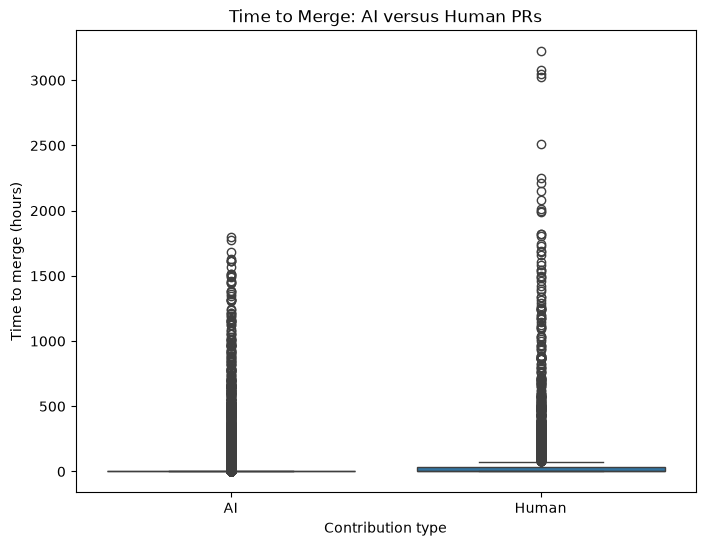

In [59]:
merge_times = time_to_merge(data)

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=merge_times,
    x="contribution_type",
    y="time_to_merge"
)

plt.title("Time to Merge: AI versus Human PRs")
plt.xlabel("Contribution type")
plt.ylabel("Time to merge (hours)")

plt.show()

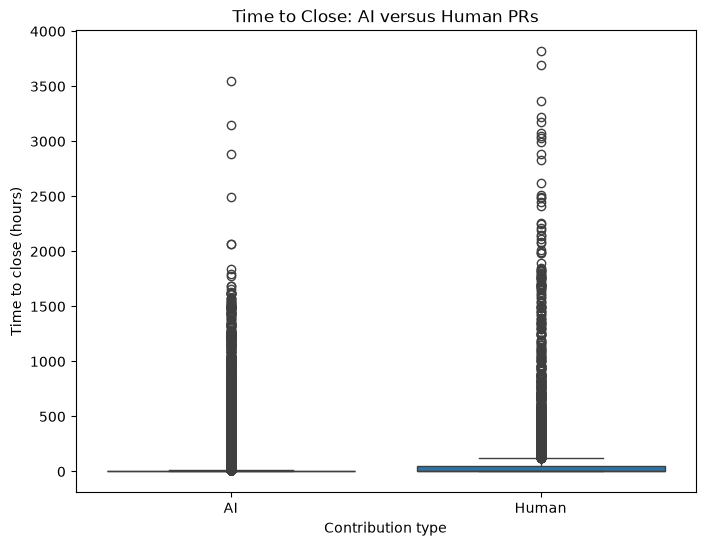

In [60]:
close_times = time_to_close(data)

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=close_times,
    x="contribution_type",
    y="time_to_close"
)

plt.title("Time to Close: AI versus Human PRs")
plt.xlabel("Contribution type")
plt.ylabel("Time to close (hours)")

plt.show()

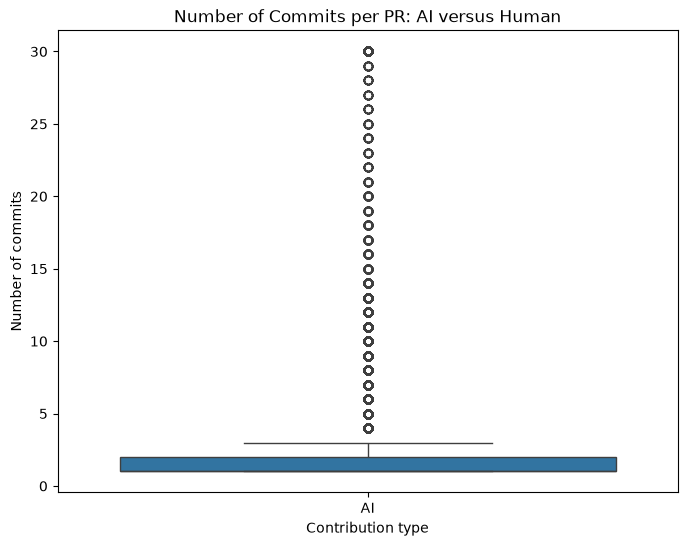

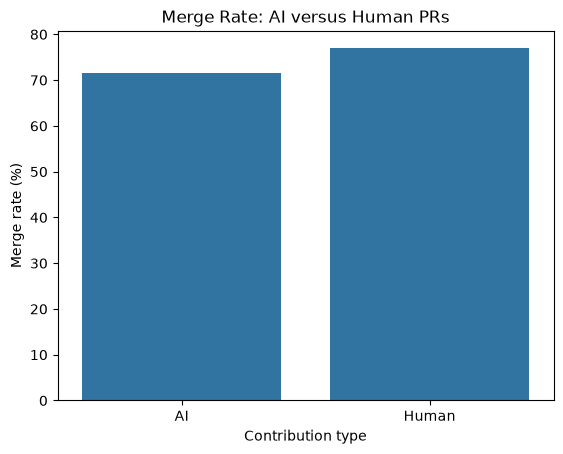

In [48]:
commits = data.dropna(subset=["n_commits"])

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=commits,
    x="contribution_type",
    y="n_commits"
)

plt.title("Number of Commits per PR: AI versus Human")
plt.xlabel("Contribution type")
plt.ylabel("Number of commits")

plt.show()

merge_results = merge_rate_by_group(data)

sns.barplot(
    data=merge_results,
    x="contribution_type",
    y="merge_rate"
)

plt.title("Merge Rate: AI versus Human PRs")
plt.xlabel("Contribution type")
plt.ylabel("Merge rate (%)")

plt.show()